# Project: Honey Production

Linear Regression track, final project. Theory and tools: [01_the_model.ipynb](01_the_model.ipynb).

US honey production 1998–2012 (Kaggle, via Codecademy): fit a linear trend to the yearly mean production and extrapolate it to 2050.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn import linear_model

df = pd.read_csv("../../data/honeyproduction.csv")

## Check out the data

**1.** `df` holds US honey production data with the columns `state`, `numcol`, `yieldpercol`, `totalprod`, `stocks`, `priceperlb`, `prodvalue`, `year`.

Use `.head()` to get a sense of how the DataFrame is structured.

In [2]:
df.head()

,state,numcol,yieldpercol,totalprod,stocks,priceperlb,prodvalue,year
0,AL,16000.0,71,1136000.0,159000.0,0.72,818000.0,1998
1,AZ,55000.0,60,3300000.0,1485000.0,0.64,2112000.0,1998
2,AR,53000.0,65,3445000.0,1688000.0,0.59,2033000.0,1998
3,CA,450000.0,83,37350000.0,12326000.0,0.62,23157000.0,1998
4,CO,27000.0,72,1944000.0,1594000.0,0.70,1361000.0,1998


**2.** We care about the total production of honey per year. Use `.groupby()` to get the mean of `totalprod` per year.

Store it in a variable called `prod_per_year`.

In [3]:
prod_per_year = df.groupby('year').totalprod.mean().reset_index()
prod_per_year.head()

,year,totalprod
0,1998,5.105093e+06
1,1999,4.706674e+06
2,2000,5.106000e+06
3,2001,4.221545e+06
4,2002,3.892386e+06


**3.** Create a variable called `X` that is the column of `year`s in `prod_per_year`.

Then reshape it into the right format for scikit-learn:

```python
X = X.values.reshape(-1, 1)
```

In [4]:
X = prod_per_year['year']
X = X.values.reshape(-1, 1)

**4.** Create a variable called `y` that is the `totalprod` column in `prod_per_year`.

In [5]:
y = prod_per_year['totalprod']

**5.** Using `plt.scatter()`, plot `y` vs `X` as a scatterplot and display it with `plt.show()`.

Can you see a vaguely linear relationship between these variables?

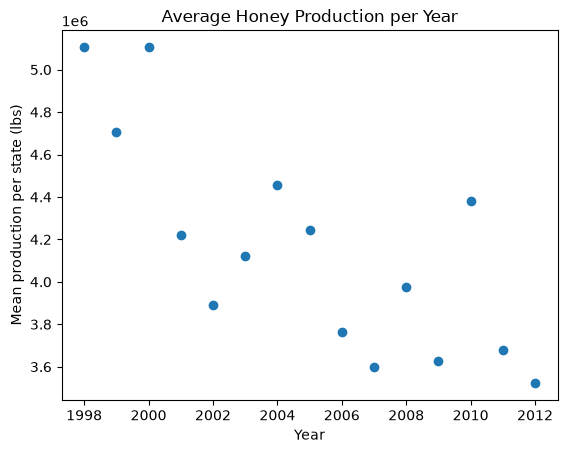

In [6]:
plt.scatter(X, y)
plt.xlabel('Year')
plt.ylabel('Mean production per state (lbs)')
plt.title('Average Honey Production per Year')
plt.show()

## Create and fit a linear regression model

**6.** Create a linear regression model from scikit-learn and call it `regr`. Use the `LinearRegression()` constructor from the `linear_model` module.

In [7]:
regr = linear_model.LinearRegression()


**7.** Fit the model to the data with `.fit()`, passing in `X` (and `y`).

In [8]:
regr.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-88303.19]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.812e+08
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[16.73]


**8.** Print the slope of the line (`regr.coef_`) and the intercept (`regr.intercept_`).

In [9]:
print(regr.coef_[0], regr.intercept_)

-88303.18915238192 181208083.10732976


**9.** Create a list called `y_predict` that holds the predictions your `regr` model makes on the `X` data.

In [10]:
y_predict = regr.predict(X)

**10.** Plot `y_predict` vs `X` as a line on top of your scatterplot with `plt.plot()`. Call `plt.show()` after plotting the line.

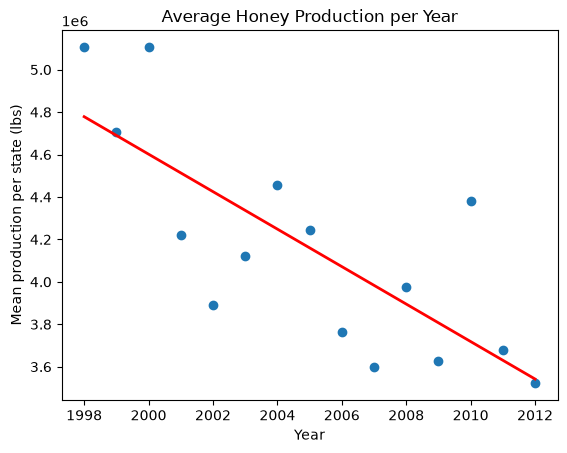

In [11]:
plt.scatter(X, y)
plt.xlabel('Year')
plt.ylabel('Mean production per state (lbs)')
plt.title('Average Honey Production per Year')
plt.plot(X, y_predict, color='red', linewidth=2)
plt.savefig("charts/honey_01_fit.png", bbox_inches="tight")   # before show()
plt.show()

## Predict the honey decline

**11.** The data stops at 2013. Create a NumPy array called `X_future` with the range from 2013 to 2050.

Example: this makes an array with the numbers 1 through 10:

```python
nums = np.array(range(1, 11))
```

Then reshape it for scikit-learn:

```python
X_future = X_future.reshape(-1, 1)
```

`reshape()` "rotates" the array: instead of one long row of numbers, `X_future` becomes a column with one number per row. Print `X_future` before and after reshaping to see the difference.

In [12]:
X_future = np.array(range(2013, 2051)).reshape(-1, 1)
print(X_future)

[[2013]
 [2014]
 [2015]
 [2016]
 [2017]
 [2018]
 [2019]
 [2020]
 [2021]
 [2022]
 [2023]
 [2024]
 [2025]
 [2026]
 [2027]
 [2028]
 [2029]
 [2030]
 [2031]
 [2032]
 [2033]
 [2034]
 [2035]
 [2036]
 [2037]
 [2038]
 [2039]
 [2040]
 [2041]
 [2042]
 [2043]
 [2044]
 [2045]
 [2046]
 [2047]
 [2048]
 [2049]
 [2050]]


**12.** Create a list called `future_predict` with the y-values your `regr` model predicts for `X_future`.

In [13]:
future_predict = regr.predict(X_future)


**13.** Plot `future_predict` vs `X_future` on a **different** plot.

How much honey will be produced in 2050, according to this model?

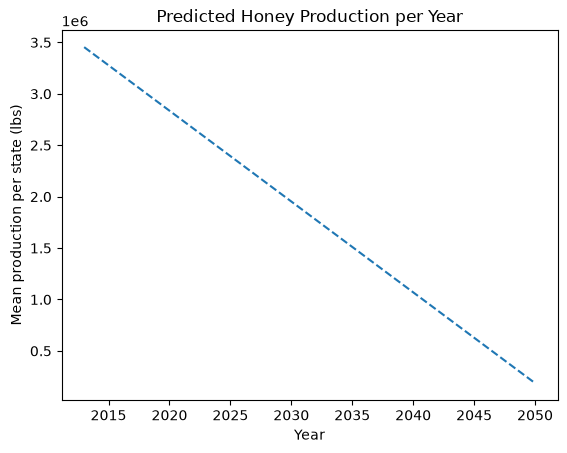

186545.34494683146
2050 prediction: 186,545 lbs


In [14]:
plt.plot(X_future, future_predict, linestyle='--')
plt.xlabel('Year')
plt.ylabel('Mean production per state (lbs)')
plt.title('Predicted Honey Production per Year')
plt.savefig("charts/honey_02_forecast_2050.png", bbox_inches="tight")   # before show()
plt.show() 

print(regr.predict([[2050]])[0])   # [[2050]] = one row, one column (2D, like X); [0] = first value of the returned array
print(f"2050 prediction: {future_predict[-1]:,.0f} lbs")   # :,.0f -> thousands separator, 0 decimals

## Results

| | value |
|---|---|
| Data | 1998–2012, 15 years; mean `totalprod` across states per year |
| Slope $m$ | −88,303 lbs per year |
| Intercept $b$ | 181,208,083 lbs (the model's value at year 0, no real meaning) |
| $R^2$ | 0.58: the trend explains just over half of the year-to-year variation |
| 1998 → 2012 (actual) | 5.11M → 3.52M lbs per state (−31%) |
| **2050 (predicted)** | **186,545 lbs per state** (−96% vs 1998) |

**Interpretation:** a straight line says production per state falls by about 88,000 lbs every year, and it reaches **zero around 2052**.

## Caveats: why not to trust the 2050 number

- **Extrapolation:** the model is fitted on 15 years and asked about a year 38 years past the data. A linear trend has no idea of limits, so it would happily predict negative honey from 2053 onwards.
- **Fit:** $R^2 = 0.58$ means a lot of variation isn't explained by "year" alone.
- **Changing sample:** the mean is taken across the states reporting each year (43 in 1998, 40 in 2012), so part of the change is which states are included, not just output.
- **Finance parallel:** this is the same risk as projecting a stock's or a company's past trend decades forward. A trend line describes the past and doesn't explain what drives it.

**Learning points**
- `groupby('year')` makes `year` the **index**, so `.reset_index()` turns it back into a column for step 3.
- `range(2013, 2050)` stops **before** 2050, so the first version ended at 2049. Stop value = last year + 1.
- `reg_fit = regr.fit(...)`: `.fit()` changes the model itself and returns it, so `reg_fit` was a second name for the same object. Use `regr` throughout.
- Reshape X **once** (step 3) instead of inline in every `fit` / `predict` call.
- `plt.scatter(..., linestyle='--')` draws no line, because scatter only draws markers. A trend or forecast line needs `plt.plot()`.
- Only the **last** line of a Jupyter cell is displayed automatically. Any other result needs `print()`.